# Exercise 1.1: Study area (2 points): Person A

Report chapter: `report/chapters/01_study_area.tex`

Study area: **Calvados (département 14, region Normandie)**.

**Sub-questions**

1. Number of observations, persons and municipalities (1 point)
2. Map of the department inside of France (1 point)

**Reads** (download as described in `data/DATA_SOURCES.md`)

- `data/raw/FD_INDCVIZB_2019.csv`: INSEE RP2019 detailed census "Individus localisés au canton-ou-ville", zone B
- `data/raw/CONTOURS-IRIS.shp`: IGN CONTOURS-IRIS 2021, metropolitan France, Lambert-93

**Writes**

- `data/processed/census_14.parquet`: detailed census, department 14 (for Ex. 1.2)
- `data/processed/iris.gpkg`, `data/processed/municipalities.gpkg`: IRIS and municipalities of department 14
- `data/processed/departments.parquet`: departments of metropolitan France (cache of the dissolve)
- `data/processed/ex11_results.json`: all numbers reported in Section 1.1
- `report/figures/ex11_location.pdf` (+ `.png` preview)

## Setup and configuration

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---- Study area ------------------------------------------------------------------------
DEPARTMENT = "14"            # INSEE code of Calvados
DEPARTMENT_NAME = "Calvados"
REGION_NAME = "Normandie"
REGION_DEPARTMENTS = ["14", "27", "50", "61", "76"]  # departments of Normandie (outlined on the map)
CRS = "EPSG:2154"            # RGF93 / Lambert-93, metres

# ---- Paths -----------------------------------------------------------------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "report").is_dir())
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "report" / "figures"

CENSUS_CSV = DATA_RAW / "FD_INDCVIZB_2019.csv"      # INSEE RP2019 detailed census, zone B
IRIS_SHP = DATA_RAW / "CONTOURS-IRIS.shp"           # IGN CONTOURS-IRIS 2021, FXX, Lambert-93

CENSUS_PARQUET = DATA_PROCESSED / f"census_{DEPARTMENT}.parquet"
IRIS_GPKG = DATA_PROCESSED / "iris.gpkg"
MUNICIPALITIES_GPKG = DATA_PROCESSED / "municipalities.gpkg"
DEPARTMENTS_PARQUET = DATA_PROCESSED / "departments.parquet"
RESULTS_JSON = DATA_PROCESSED / "ex11_results.json"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# ---- Figures ---------------------------------------------------------------------------
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "legend.fontsize": 8, "pdf.fonttype": 42,
})


def style_map_axes(ax):
    # Common map look: equal aspect, no axes frame or ticks
    ax.set_aspect("equal")
    ax.set_axis_off()
    return ax


def save_figure(fig, name, preview_png=False):
    # Vector PDF for the report (report/figures/<name>.pdf, \includegraphics{<name>}), optional PNG preview
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"{name}.pdf"
    fig.savefig(path, format="pdf", bbox_inches="tight")
    if preview_png:
        fig.savefig(path.with_suffix(".png"), format="png", dpi=150, bbox_inches="tight")
    return path


print("Study area:", DEPARTMENT, DEPARTMENT_NAME, f"({REGION_NAME})")

Study area: 14 Calvados (Normandie)


## 1. Number of observations, persons and municipalities (1 point)

### Load the detailed census

As in the course notebook `01 Exploration`, only the needed columns are read with explicit dtypes (codes as `str`:
leading zeros, `2A`/`2B`, placeholders such as `ZZZZZZZZZ`) and then renamed. Calvados belongs to **zone B**
(Centre-Val de Loire, Bourgogne-Franche-Comté, Normandie, Hauts-de-France), so the zone B file is filtered on
`DEPT == "14"`. The file is about 930 MB, so it is read in chunks. `AGED` and `CS1` are kept for Exercise 1.2. Column names as in the course notebook (`csp` for `CS1`).

In [2]:
columns = {
    "DEPT": str,
    "CANTVILLE": str,
    "IRIS": str,
    "IPONDI": float,

    "AGED": int,
    "CS1": int,
}

chunks = pd.read_csv(CENSUS_CSV, sep=";", usecols=columns.keys(), dtype=columns, chunksize=1_000_000)
df_census = pd.concat([chunk[chunk["DEPT"] == DEPARTMENT] for chunk in chunks], ignore_index=True)

df_census = df_census.rename(columns={
    "DEPT": "department",
    "CANTVILLE": "cantville",
    "IRIS": "iris_id",
    "IPONDI": "weight",

    "AGED": "age",
    "CS1": "csp",
})

# Municipality = first five characters of the IRIS code; unknown where IRIS = ZZZZZZZZZ (see (3))
IRIS_NOT_IDENTIFIED = "ZZZZZZZZZ"
not_split = df_census["iris_id"] == IRIS_NOT_IDENTIFIED
df_census["municipality_id"] = df_census["iris_id"].str[:5].where(~not_split)

assert (df_census["department"] == DEPARTMENT).all()
assert df_census["iris_id"].str.len().eq(9).all()

df_census.to_parquet(CENSUS_PARQUET)
print("saved", CENSUS_PARQUET.relative_to(ROOT))
df_census.head()

saved data\processed\census_14.parquet


,cantville,age,csp,department,weight,iris_id,municipality_id
0,1401,92,7,14,5.000000,ZZZZZZZZZ,NaN
1,1401,72,7,14,5.120056,ZZZZZZZZZ,NaN
2,1401,70,7,14,5.120056,ZZZZZZZZZ,NaN
3,1401,32,5,14,5.161397,ZZZZZZZZZ,NaN
4,1401,27,6,14,5.161397,ZZZZZZZZZ,NaN


### (1) Person observations and (2) persons living in the department

An observation is one row of the file. The number of persons is the **sum of the weights** `IPONDI`.

In [3]:
n_observations = len(df_census)
n_persons = df_census["weight"].sum()
mean_weight = df_census["weight"].mean()

print(f"(1) Person observations (rows):          {n_observations}")
print(f"(2) Persons (sum of IPONDI):             {n_persons}")
print(f"    Mean weight (persons / observation): {mean_weight}")

(1) Person observations (rows):          171834
(2) Persons (sum of IPONDI):             695131.5553559497
    Mean weight (persons / observation): 4.045366780473886


Why (1) ≠ (2): the detailed file comes from the rotating census survey (five annual collection rounds), and each row
stands for `IPONDI` persons. Municipalities with fewer than 10,000 inhabitants are surveyed exhaustively once every five
years in rotation; in municipalities with 10,000 inhabitants or more a sample of dwellings is surveyed every year. The
weights therefore differ by municipality size, as the table below shows. Size classes use the weighted RP2019
population of the municipality; it can only be computed for municipalities that are identifiable in the file (see (3)).

In [4]:
pop_by_municipality = df_census.groupby("municipality_id")["weight"].sum()
large = df_census["municipality_id"].map(pop_by_municipality).ge(10_000)
size_class = np.select(
    [not_split, large],
    ["not split into IRIS (IRIS = ZZZZZZZZZ)", "split into IRIS, >= 10,000 inhabitants"],
    default="split into IRIS, < 10,000 inhabitants",
)
weight_by_group = (
    df_census.assign(group=size_class)
    .groupby("group")
    .agg(municipalities=("municipality_id", "nunique"), observations=("weight", "size"),
         persons=("weight", "sum"), mean_weight=("weight", "mean"),
         min_weight=("weight", "min"), max_weight=("weight", "max"))
)
weight_by_group

,municipalities,observations,persons,mean_weight,min_weight,max_weight
group,,,,,,
not split into IRIS (IRIS = ZZZZZZZZZ),0,86278,433173.620062,5.020673,1.666667,7.111131
"split into IRIS, < 10,000 inhabitants",11,14479,72183.337700,4.985381,3.333239,6.416911
"split into IRIS, >= 10,000 inhabitants",6,71077,189774.597594,2.669986,0.500003,7.500028


### (3) Number of municipalities

**Main answer, from the IGN CONTOURS-IRIS 2021 file.** This is the geography in which RP2019 is published. Every
municipality has at least one IRIS polygon (municipalities that are not split have a single IRIS `<code>0000`), so
the unique `INSEE_COM` with prefix `14` give the number of municipalities. As in the course notebook, the columns are
renamed; `NOM_COM` (name) and `TYP_IRIS` (IRIS type) are kept as well.

In [5]:
df_iris_france = gpd.read_file(IRIS_SHP)
df_iris_france = df_iris_france.rename(columns={
    "CODE_IRIS": "iris_id",
    "INSEE_COM": "municipality_id",
    "NOM_COM": "name",
    "NOM_IRIS": "iris_name",
    "TYP_IRIS": "iris_type",
})[["iris_id", "municipality_id", "name", "iris_name", "iris_type", "geometry"]]

# The .prj declares IGNF:LAMB93, which is the same CRS as EPSG:2154
assert df_iris_france.crs.equals(CRS)
df_iris_france = df_iris_france.set_crs(CRS, allow_override=True)
print("IRIS in metropolitan France:", len(df_iris_france),
      "| municipalities:", df_iris_france["municipality_id"].nunique())

df_iris = df_iris_france[df_iris_france["municipality_id"].str[:2] == DEPARTMENT].reset_index(drop=True)
n_iris_ign = len(df_iris)
n_municipalities_ign = df_iris["municipality_id"].nunique()

print(f"IRIS in department {DEPARTMENT} (IGN 2021):              {n_iris_ign}")
print(f"(3) Municipalities in department {DEPARTMENT} (IGN 2021): {n_municipalities_ign}")
print("IRIS types (TYP_IRIS):", df_iris["iris_type"].value_counts().to_dict())

IRIS in metropolitan France: 48589 | municipalities: 34878
IRIS in department 14 (IGN 2021):              656
(3) Municipalities in department 14 (IGN 2021): 528
IRIS types (TYP_IRIS): {'Z': 511, 'H': 123, 'A': 18, 'D': 4}


**From the census file.** In the canton-ou-ville file, the municipality can only be read from `IRIS[:5]`.
Persons living in a municipality that is **not split into IRIS** have `IRIS == "ZZZZZZZZZ"`, so their municipality is
unknown (only the canton-ou-ville is known). Codes `<municipality>XXXX` (IRIS with fewer than 200 inhabitants) still
identify the municipality. `municipality_id` is therefore missing exactly where `IRIS == "ZZZZZZZZZ"`.

In [6]:
identified = df_census["municipality_id"].notna()
assert (identified == ~not_split).all()

n_municipalities_census = df_census.loc[identified, "municipality_id"].nunique()
n_iris_xxxx = df_census["iris_id"].str.endswith("XXXX").sum()
persons_identified = df_census.loc[identified, "weight"].sum()
share_persons_identified = persons_identified / n_persons
share_observations_identified = identified.mean()

print(f"Municipalities identifiable in the census (IRIS[:5], without ZZZZZZZZZ): {n_municipalities_census}")
print(f"  observations with IRIS == ZZZZZZZZZ:            {not_split.sum()}")
print(f"  observations with IRIS code ending in XXXX:     {n_iris_xxxx}")
print(f"  persons in identifiable municipalities:         {persons_identified}")
print(f"  share of persons (weighted) identifiable:       {share_persons_identified}")
print(f"  share of observations identifiable:             {share_observations_identified}")

Municipalities identifiable in the census (IRIS[:5], without ZZZZZZZZZ): 17
  observations with IRIS == ZZZZZZZZZ:            86278
  observations with IRIS code ending in XXXX:     212
  persons in identifiable municipalities:         261957.93529419604
  share of persons (weighted) identifiable:       0.3768465598717607
  share of observations identifiable:             0.49789913521189055


The identifiable municipalities are exactly the municipalities that are split into IRIS. With their names from the IGN file:

In [7]:
municipality_names = df_iris.drop_duplicates("municipality_id").set_index("municipality_id")["name"]
df_identified = (
    df_census[identified]
    .groupby("municipality_id")["weight"]
    .agg(observations="size", persons="sum", mean_weight="mean")
    .join(municipality_names)
    .sort_values("persons", ascending=False)
)
df_identified

,observations,persons,mean_weight,name
municipality_id,,,,
14118,39384,106233.646411,2.697381,Caen
14327,8134,22559.000074,2.773420,Hérouville-Saint-Clair
14366,7847,20039.999954,2.553842,Lisieux
14762,6245,16574.716721,2.654078,Vire Normandie
14047,5004,12666.999916,2.531375,Bayeux
14341,4463,11700.234518,2.621608,Ifs
14437,2010,9967.611743,4.959011,Mondeville
14488,1878,9295.792029,4.949836,Ouistreham
14258,1562,7928.502147,5.075866,Falaise


**Check: the department filter of the course notebook.** The course notebook `01 Exploration` derives the department
from the IRIS code (`iris_id.str[:2]`) instead of reading `DEPT`. For Calvados this silently drops every person whose
IRIS is `ZZZZZZZZZ` (their "department" becomes `ZZ`). That is why we filter on `DEPT`:

In [8]:
course_filter = df_census["iris_id"].str[:2] == DEPARTMENT   # course approach
n_observations_course = int(course_filter.sum())
n_persons_course = df_census.loc[course_filter, "weight"].sum()
share_persons_lost_course = 1 - n_persons_course / n_persons

print(f"Course approach (IRIS[:2] == '{DEPARTMENT}'): {n_observations_course} observations, {n_persons_course} persons, "
      f"{df_census.loc[course_filter, 'municipality_id'].nunique()} municipalities")
print(f"Our approach (DEPT == '{DEPARTMENT}'):       {n_observations} observations, {n_persons} persons")
print(f"Share of persons lost by the course approach: {share_persons_lost_course}")

Course approach (IRIS[:2] == '14'): 85556 observations, 261957.93529419604 persons, 17 municipalities
Our approach (DEPT == '14'):       171834 observations, 695131.5553559497 persons
Share of persons lost by the course approach: 0.6231534401282393


**Join checks** (codes of the census against the IGN 2021 geography).

In [9]:
ign_municipalities = set(df_iris["municipality_id"])
ign_iris = set(df_iris["iris_id"])
census_municipalities = set(df_census.loc[identified, "municipality_id"])
census_iris = set(df_census.loc[identified & ~df_census["iris_id"].str.endswith("XXXX"), "iris_id"])

print("census municipalities not in IGN 2021:", sorted(census_municipalities - ign_municipalities))
print("census IRIS codes (without XXXX) not in IGN 2021:", sorted(census_iris - ign_iris))

# Municipalities split into IRIS in the IGN file (IRIS type other than Z)
split_in_ign = set(df_iris.loc[df_iris["iris_type"] != "Z", "municipality_id"])
print("split into IRIS in IGN 2021:", len(split_in_ign),
      "| same set as identifiable in census:", split_in_ign == census_municipalities)

census municipalities not in IGN 2021: []
census IRIS codes (without XXXX) not in IGN 2021: []
split into IRIS in IGN 2021: 17 | same set as identifiable in census: True


**Sanity check: canton-ou-ville codes.** Every person is localised at least at this level.

In [10]:
n_cantville = df_census["cantville"].nunique()
print(f"CANTVILLE codes in department {DEPARTMENT}: {n_cantville}")
df_cantville = (
    df_census.assign(identified=identified)
    .groupby("cantville")
    .agg(observations=("weight", "size"), persons=("weight", "sum"),
         share_identified=("identified", "mean"), municipalities=("municipality_id", "nunique"))
)
df_cantville

CANTVILLE codes in department 14: 26


,observations,persons,share_identified,municipalities
cantville,,,,
1401,4222,21057.048177,0.000000,0
1402,8221,28860.274908,0.608685,1
1403,5535,28135.195303,0.000000,0
1404,5962,29793.077178,0.176954,1
1405,2048,10401.997510,0.000000,0
1406,2007,10181.250872,0.000000,0
1407,322,1601.645067,0.000000,0
1409,2219,11129.135608,0.445246,1
1410,4792,23315.075141,0.289023,1


### Validation against the official figures

The numbers are checked against the official INSEE **legal populations 2019** for Calvados (reference date 1 January
2019, communes in their limits of 1 January 2021, decree n° 2021-1946 of 31 December 2021), document
"Populations légales en vigueur à compter du 1er janvier 2022, 14 Calvados" (INSEE, December 2021),
<https://www.insee.fr/fr/statistiques/fichier/6011060/dep14.pdf>, Tables 1 and 3. The values below are copied from
that document (population municipale, which is the population the census weights refer to).

In [11]:
OFFICIAL_SOURCE = "INSEE, Populations légales 2019, 14 Calvados (Dec. 2021), https://www.insee.fr/fr/statistiques/fichier/6011060/dep14.pdf"
OFFICIAL_N_MUNICIPALITIES = 528          # Table 1, "TOTAL DU DEPARTEMENT", nombre de communes
OFFICIAL_POPULATION = 694_905            # Table 1, "TOTAL DU DEPARTEMENT", population municipale
OFFICIAL_POPULATION_MUNICIPALITIES = {   # Table 3, population municipale
    "14118": 106_230,  # Caen
    "14327": 22_555,   # Hérouville-Saint-Clair
    "14366": 20_038,   # Lisieux
    "14762": 16_590,   # Vire Normandie
    "14047": 12_682,   # Bayeux
    "14341": 11_696,   # Ifs
    "14437": 9_973,    # Mondeville
    "14488": 9_344,    # Ouistreham
    "14258": 7_968,    # Falaise
    "14167": 6_976,    # Colombelles
    "14333": 6_733,    # Honfleur
    "14174": 6_452,    # Condé-en-Normandie
    "14225": 5_276,    # Dives-sur-Mer
    "14271": 4_938,    # Fleury-sur-Orne
    "14181": 4_957,    # Cormelles-le-Royal
    "14301": 4_916,    # Giberville
    "14715": 4_603,    # Trouville-sur-Mer
}

print(f"Municipalities: ours {n_municipalities_ign}, official {OFFICIAL_N_MUNICIPALITIES}, "
      f"equal: {n_municipalities_ign == OFFICIAL_N_MUNICIPALITIES}")
diff_population = n_persons - OFFICIAL_POPULATION
print(f"Persons:        ours {n_persons}, official {OFFICIAL_POPULATION}, "
      f"difference {diff_population} ({diff_population / OFFICIAL_POPULATION:.4%})")

df_validation = df_identified[["name", "persons"]].copy()
df_validation["official"] = pd.Series(OFFICIAL_POPULATION_MUNICIPALITIES)
assert df_validation["official"].notna().all()
df_validation["difference"] = df_validation["persons"] - df_validation["official"]
df_validation["relative_difference"] = df_validation["difference"] / df_validation["official"]
df_validation["size_class"] = np.where(df_validation["official"] >= 10_000, ">= 10,000", "< 10,000")
print("max |relative difference| by size class:")
print(df_validation.groupby("size_class")["relative_difference"].apply(lambda x: x.abs().max()))
df_validation

Municipalities: ours 528, official 528, equal: True
Persons:        ours 695131.5553559497, official 694905, difference 226.5553559496766 (0.0326%)
max |relative difference| by size class:
size_class
< 10,000     0.011796
>= 10,000    0.001183
Name: relative_difference, dtype: float64


,name,persons,official,difference,relative_difference,size_class
municipality_id,,,,,,
14118,Caen,106233.646411,106230,3.646411,0.000034,">= 10,000"
14327,Hérouville-Saint-Clair,22559.000074,22555,4.000074,0.000177,">= 10,000"
14366,Lisieux,20039.999954,20038,1.999954,0.000100,">= 10,000"
14762,Vire Normandie,16574.716721,16590,-15.283279,-0.000921,">= 10,000"
14047,Bayeux,12666.999916,12682,-15.000084,-0.001183,">= 10,000"
14341,Ifs,11700.234518,11696,4.234518,0.000362,">= 10,000"
14437,Mondeville,9967.611743,9973,-5.388257,-0.000540,"< 10,000"
14488,Ouistreham,9295.792029,9344,-48.207971,-0.005159,"< 10,000"
14258,Falaise,7928.502147,7968,-39.497853,-0.004957,"< 10,000"


### Municipalities of the study area (for Exercises 1.2 to 2.2)

As in the course notebook, municipalities are obtained by dissolving the IRIS on `municipality_id`. They are sorted
by `municipality_id`, which fixes the zone order of the pipeline.

In [12]:
df_municipalities = (
    df_iris[["municipality_id", "name", "geometry"]]
    .dissolve("municipality_id", aggfunc="first")
    .reset_index()
    .sort_values("municipality_id", ignore_index=True)
)
assert len(df_municipalities) == n_municipalities_ign

df_iris.to_file(IRIS_GPKG, driver="GPKG")
df_municipalities.to_file(MUNICIPALITIES_GPKG, driver="GPKG")
print("saved", IRIS_GPKG.relative_to(ROOT), len(df_iris), "IRIS")
print("saved", MUNICIPALITIES_GPKG.relative_to(ROOT), len(df_municipalities), "municipalities")

saved data\processed\iris.gpkg 656 IRIS
saved data\processed\municipalities.gpkg 528 municipalities


## 2. Map of the department inside of France (1 point)

Departments are built by dissolving all IRIS of metropolitan France on `municipality_id[:2]` (`2A`/`2B` for Corsica).
The default dissolve (unary union) took about 26 s in a test run; because IRIS form a clean coverage (no overlaps,
shared edges match exactly), `method="coverage"` gives the same geometry in a few seconds (checked below). The result
is cached anyway.

In [13]:
if DEPARTMENTS_PARQUET.exists():
    df_departments = gpd.read_parquet(DEPARTMENTS_PARQUET)
    print("read cache", DEPARTMENTS_PARQUET.relative_to(ROOT))
else:
    t0 = time.perf_counter()
    df_departments = (
        df_iris_france[["municipality_id", "geometry"]]
        .assign(department_id=df_iris_france["municipality_id"].str[:2])
        .dissolve("department_id", method="coverage")
        .reset_index()[["department_id", "geometry"]]
        .sort_values("department_id", ignore_index=True)
    )
    print(f"coverage dissolve: {time.perf_counter() - t0:.1f} s")
    df_departments.to_parquet(DEPARTMENTS_PARQUET)
    print("saved", DEPARTMENTS_PARQUET.relative_to(ROOT))

print("departments:", len(df_departments))
assert len(df_departments) == 96  # metropolitan France, incl. 2A/2B

read cache data\processed\departments.parquet
departments: 96


In [14]:
# Check of the coverage dissolve against the default unary union for the departments of Normandie
# (the full France-wide unary union is the slow part; Normandie is enough to check the method).
normandie_iris = df_iris_france[df_iris_france["municipality_id"].str[:2].isin(REGION_DEPARTMENTS)]
unary = normandie_iris.assign(department_id=normandie_iris["municipality_id"].str[:2]).dissolve("department_id")
coverage = df_departments.set_index("department_id").loc[unary.index]
sym_diff_area = coverage.geometry.symmetric_difference(unary.geometry, align=True).area
print("max symmetric difference area (m2) coverage vs unary dissolve:", sym_diff_area.max())

max symmetric difference area (m2) coverage vs unary dissolve: 0.0


Map: all departments in light grey, the region Normandie outlined, Calvados highlighted (left); Calvados with its
municipality boundaries and its main towns (right). For the France map the department geometries are simplified with
`simplify_coverage` (500 m), which keeps shared boundaries identical. Lambert-93 (EPSG:2154).

                           name
municipality_id                
14118                      Caen
14047                    Bayeux
14366                   Lisieux
14762            Vire Normandie


saved report\figures\ex11_location.pdf and report\figures\ex11_location.png


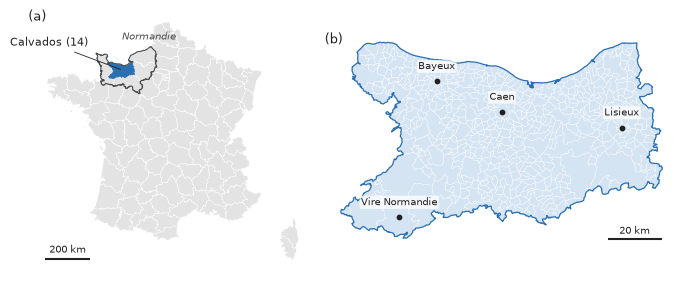

In [15]:
# Style: neutral greys, one accent colour for the study area, text in a text colour
GREY_FILL, GREY_EDGE = "#e3e3e3", "#ffffff"
ACCENT, ACCENT_LIGHT = "#2a6fb0", "#d5e4f2"
OUTLINE, TEXT = "#4d4d4d", "#222222"

departments_plot = df_departments.copy()
departments_plot["geometry"] = departments_plot.geometry.simplify_coverage(500)
calvados = departments_plot[departments_plot["department_id"] == DEPARTMENT]
normandie = departments_plot[departments_plot["department_id"].isin(REGION_DEPARTMENTS)].dissolve()

towns = {  # main centre and secondary centres (municipality codes, IGN 2021)
    "14118": "Caen",
    "14047": "Bayeux",
    "14366": "Lisieux",
    "14762": "Vire Normandie",
}
df_towns = df_municipalities.set_index("municipality_id").loc[list(towns)]
df_towns["geometry"] = df_towns.geometry.representative_point()
print(df_towns[["name"]])


def scale_bar(ax, length_m, label, x_frac=0.06, y_frac=0.05):
    # Simple scale bar in map units (metres, Lambert-93)
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    ax.plot([x, x + length_m], [y, y], color=TEXT, lw=1.5, solid_capstyle="butt")
    ax.text(x + length_m / 2, y + 0.015 * (y1 - y0), label, ha="center", va="bottom", fontsize=7, color=TEXT)


fig, (ax_fr, ax_14) = plt.subplots(1, 2, figsize=(7.0, 3.6), gridspec_kw={"width_ratios": [1.0, 1.25]})

# Left: France
departments_plot.plot(ax=ax_fr, color=GREY_FILL, edgecolor=GREY_EDGE, linewidth=0.3)
calvados.plot(ax=ax_fr, color=ACCENT, edgecolor=ACCENT, linewidth=0.3)
normandie.boundary.plot(ax=ax_fr, color=OUTLINE, linewidth=0.8)
cx, cy = calvados.geometry.iloc[0].representative_point().coords[0]
ax_fr.annotate("Calvados (14)", xy=(cx, cy), xytext=(cx - 330_000, cy + 110_000), fontsize=8, color=TEXT,
               ha="center", arrowprops=dict(arrowstyle="-", color=TEXT, lw=0.6))
nx_, ny_ = normandie.geometry.iloc[0].centroid.coords[0]
ax_fr.text(nx_ + 90_000, ny_ + 135_000, "Normandie", fontsize=7, color=OUTLINE, style="italic", ha="center")
style_map_axes(ax_fr)
scale_bar(ax_fr, 200_000, "200 km")

# Right: Calvados with its municipalities
df_municipalities.plot(ax=ax_14, color=ACCENT_LIGHT, edgecolor="white", linewidth=0.25)
df_municipalities.dissolve().boundary.plot(ax=ax_14, color=ACCENT, linewidth=0.9)
df_towns.plot(ax=ax_14, color=TEXT, markersize=10, zorder=3)
for _, row in df_towns.iterrows():
    ax_14.text(row.geometry.x, row.geometry.y + 4500, row["name"], fontsize=7, color=TEXT, ha="center",
               bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
style_map_axes(ax_14)
scale_bar(ax_14, 20_000, "20 km", x_frac=0.80, y_frac=0.04)

ax_fr.text(0.0, 1.0, "(a)", transform=ax_fr.transAxes, fontsize=9, va="top", color=TEXT)
ax_14.text(0.0, 1.0, "(b)", transform=ax_14.transAxes, fontsize=9, va="top", color=TEXT)
fig.tight_layout()

path = save_figure(fig, "ex11_location", preview_png=True)
print("saved", path.relative_to(ROOT), "and", path.with_suffix(".png").relative_to(ROOT))
plt.show()

## Results for the report

All numbers of Section 1.1 come from this file (unrounded).

In [16]:
results = {
    "department": DEPARTMENT,
    "department_name": DEPARTMENT_NAME,
    "census_file": CENSUS_CSV.name,
    "iris_file": "CONTOURS-IRIS 2021 (CONTOURS-IRIS_2-1_SHP_LAMB93_FXX-2021)",
    "n_observations": int(n_observations),
    "n_persons_weighted": float(n_persons),
    "mean_weight": float(mean_weight),
    "mean_weight_not_split": float(df_census.loc[not_split, "weight"].mean()),
    "mean_weight_iris": float(df_census.loc[~not_split, "weight"].mean()),
    "n_municipalities_ign2021": int(n_municipalities_ign),
    "n_iris_ign2021": int(n_iris_ign),
    "n_municipalities_identifiable_census": int(n_municipalities_census),
    "n_observations_iris_zzzzzzzzz": int(not_split.sum()),
    "n_observations_iris_xxxx": int(n_iris_xxxx),
    "n_persons_identifiable": float(persons_identified),
    "share_persons_identifiable": float(share_persons_identified),
    "share_observations_identifiable": float(share_observations_identified),
    "n_cantville": int(n_cantville),
    "n_departments_metropolitan": int(len(df_departments)),
    "course_approach_iris2": {
        "n_observations": n_observations_course,
        "n_persons": float(n_persons_course),
        "share_persons_lost": float(share_persons_lost_course),
    },
    "validation": {
        "source": OFFICIAL_SOURCE,
        "official_n_municipalities": OFFICIAL_N_MUNICIPALITIES,
        "official_population_municipale": OFFICIAL_POPULATION,
        "difference_persons": float(diff_population),
        "relative_difference_persons": float(diff_population / OFFICIAL_POPULATION),
        "municipalities": {
            k: {"name": v["name"], "ours": float(v["persons"]), "official": int(v["official"]),
                "relative_difference": float(v["relative_difference"])}
            for k, v in df_validation.to_dict("index").items()
        },
    },
    "weights_by_municipality_type": {
        k: {kk: (float(vv) if not isinstance(vv, (int, np.integer)) else int(vv)) for kk, vv in v.items()}
        for k, v in weight_by_group.to_dict("index").items()
    },
    "identifiable_municipalities": {
        k: {"name": v["name"], "observations": int(v["observations"]), "persons": float(v["persons"])}
        for k, v in df_identified.to_dict("index").items()
    },
}
RESULTS_JSON.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", RESULTS_JSON.relative_to(ROOT))
{k: v for k, v in results.items() if k not in ("identifiable_municipalities", "weights_by_municipality_type", "validation")}

saved data\processed\ex11_results.json


{'department': '14',
 'department_name': 'Calvados',
 'census_file': 'FD_INDCVIZB_2019.csv',
 'iris_file': 'CONTOURS-IRIS 2021 (CONTOURS-IRIS_2-1_SHP_LAMB93_FXX-2021)',
 'n_observations': 171834,
 'n_persons_weighted': 695131.5553559497,
 'mean_weight': 4.045366780473886,
 'mean_weight_not_split': 5.020672941674049,
 'mean_weight_iris': 3.0618300913342846,
 'n_municipalities_ign2021': 528,
 'n_iris_ign2021': 656,
 'n_municipalities_identifiable_census': 17,
 'n_observations_iris_zzzzzzzzz': 86278,
 'n_observations_iris_xxxx': 212,
 'n_persons_identifiable': 261957.93529419604,
 'share_persons_identifiable': 0.3768465598717607,
 'share_observations_identifiable': 0.49789913521189055,
 'n_cantville': 26,
 'n_departments_metropolitan': 96,
 'course_approach_iris2': {'n_observations': 85556,
  'n_persons': 261957.93529419604,
  'share_persons_lost': 0.6231534401282393}}

## Problems encountered

- **Which census file.** INSEE splits the detailed file into zones; Calvados (Normandie) is in **zone B**
  (`FD_INDCVIZB_2019.csv`, ~930 MB for four regions), not zone A as in the course notebook. It is read in chunks with
  `usecols` and filtered on `DEPT == "14"`.
- **Department filter of the course notebook.** Taking the department from `IRIS[:2]` as in the course notebook
  drops all persons in municipalities not split into IRIS (`IRIS = ZZZZZZZZZ`); for Calvados it would have kept only a
  minority of the population (numbers in (3)). We filter on the column `DEPT` instead.
- **Municipalities not identifiable in the census.** About half of the observations have `IRIS == "ZZZZZZZZZ"`
  (municipality not split into IRIS); their municipality is unknown. See (3) for how many municipalities and which
  share of the weighted population remain identifiable. This matters for every municipality-level statistic of
  Exercise 1.2.
- **Slow dissolve.** Dissolving all 48,589 IRIS of metropolitan France into departments with the default `dissolve`
  took about 26 s in a test run; `dissolve(method="coverage")` gives the identical geometry (symmetric difference of
  area 0) in a few seconds. The result is cached in `data/processed/departments.parquet`.
- **Unpacking the IGN archive on Windows.** 7-Zip was not installed, so the archive was unpacked with the Python package
  `py7zr`. Extracting inside the project folder failed because the nested folder names of the archive exceed the
  Windows 260-character path limit; extracting into a short temporary folder and copying only `CONTOURS-IRIS.*` works.
- **Codes.** All identifiable census municipalities and IRIS codes exist in IGN CONTOURS-IRIS 2021 (join checks above),
  so there is no code mismatch between RP2019 and the 2021 geography for Calvados.